# Lab 2-03：結構化輸出——用 SDK 拿到驗證過的 Pydantic 物件

**目標**：把口語的事故回報轉成程式能直接用的物件。先看「請輸出 JSON」怎麼壞，然後直接用 OpenAI SDK 的
`parse()` 與 Ollama 的 `format` 參數，把 Pydantic 類別交給模型；最後補上驗證失敗的重試。

**你會學到**
- 一個 Pydantic 類別兩頭用：產生 JSON Schema 約束模型、把回應驗證成物件
- `client.chat.completions.parse(response_format=類別)` 與 `ollama.chat(format=schema)` 的用法
- schema 表達不了的業務規則寫在 Pydantic，不過就把錯誤回饋給模型重試
- 輸出被截斷（`finish_reason="length"`）時，格式保證就不成立
- 「通過驗證」不等於「內容正確」

**前置**：Lab 2-01；原理見 `00_concepts.md` 的「結構化輸出」一節。本機 Ollama 有 `qwen2.5:3b`。

**對應投影片**：「結構化輸出三層保障」「選型：結構化輸出工具」「Lab2：結構定義」「踩坑：吐字與覆蓋」

![結構化輸出的三層保障](images/structured_layers.jpg)

*圖：三層疊著用，由下往上保證越強：提示詞只是要求（會多吐字）、JSON Schema 約束解碼保證格式（但會被截斷）、Pydantic 驗證業務規則（不過就把錯誤回饋給模型重試，朱紅箭頭）。SDK 的 parse() 一次做完第 2、3 層。*

## Step 1：先看它壞掉

情境：值班同學用口語寫事故回報，要轉成結構化資料存進資料庫。只在 prompt 裡要求 JSON，然後 `json.loads`：

In [1]:
import json
import os
import time

from openai import LengthFinishReasonError

from course_utils.llm import chat

report = "下午兩點半左右付款那邊開始報錯，大約持續了一個半小時，客服估計有三千多位使用者受影響，判定為 P1。"

PROMPT = """從 <report> 抽出事故資訊，輸出 JSON，欄位：
service（服務名稱）、severity（P1/P2/P3）、start_time（HH:MM，24 小時制）、
duration_min（整數分鐘）、affected_users（整數）。
<report>{report}</report>"""

raw = chat([{"role": "user", "content": PROMPT.format(report=report)}])
print(raw)
try:
    json.loads(raw)
except json.JSONDecodeError as exc:
    print(f"\nJSONDecodeError：{exc.msg}（第 {exc.lineno} 行第 {exc.colno} 欄）→ 那裡是：{raw.splitlines()[exc.lineno - 1]!r}")

```json
[
    {
        "service": "付款服務",
        "severity": "P1",
        "start_time": "14:30",
        "duration_min": 30,
        "affected_users": 3000
    }
]
```

JSONDecodeError：Expecting value（第 1 行第 1 欄）→ 那裡是：'```json'


對話模型被訓練成「回答人類」，客套話和 ```` ```json ```` 外框對人很友善，對 `json.loads` 是錯誤。
以前的解法是用正規表示式把 `{...}` 摳出來，很脆弱。現在主流 API 都有原生的結構化輸出，直接用。

## Step 2：用 Pydantic 寫下規格

每個欄位的型別與限制寫在類別裡：`Literal` 限定選項、`pattern` 限定字串格式、`ge=0` 不能是負數。

兩個 JSON Schema 管不到、要在程式端處理的規則：
- **服務名稱必須是服務目錄裡的正式名稱**。回報裡寫的是「付款那邊」「站內搜尋」，資料庫要的是「付款服務」「搜尋服務」。
  目錄會隨公司調整，所以放在 `field_validator` 對照清單，不寫死在 schema。
- **結束時間由程式算**。時間加減是 3B 模型的弱項（試過讓它自己填 `end_time`，回饋三次還是算錯），
  能用程式算的就不要讓模型算：用 `computed_field`，模型不用輸出，物件自己算。

In [2]:
from typing import Literal

from pydantic import BaseModel, Field, ValidationError, computed_field, field_validator

SERVICE_CATALOG = ["付款服務", "帳務服務", "登入服務", "會員服務", "推播服務", "搜尋服務", "報表服務", "檔案上傳服務"]


class Incident(BaseModel):
    service: str = Field(description="服務目錄裡的正式名稱")
    severity: Literal["P1", "P2", "P3"] = Field(description="P1 最嚴重")
    start_time: str = Field(pattern=r"^\d{2}:\d{2}$", description="開始時間 HH:MM，24 小時制")
    duration_min: int = Field(ge=0, description="持續分鐘數")
    affected_users: int = Field(ge=0, description="受影響人數")

    @field_validator("service")
    @classmethod
    def in_catalog(cls, v: str) -> str:
        if v not in SERVICE_CATALOG:
            raise ValueError(f"service 必須是服務目錄裡的正式名稱之一：{'、'.join(SERVICE_CATALOG)}；你給的是「{v}」")
        return v

    @computed_field
    @property
    def end_time(self) -> str:
        h, m = map(int, self.start_time.split(":"))
        t = (h * 60 + m + self.duration_min) % (24 * 60)
        return f"{t // 60:02d}:{t % 60:02d}"


# 點一下：Pydantic 自動產生的 JSON Schema，就是等一下要交給模型的東西
print(json.dumps(Incident.model_json_schema(), ensure_ascii=False, indent=1)[:700], "...")

{
 "properties": {
  "service": {
   "description": "服務目錄裡的正式名稱",
   "title": "Service",
   "type": "string"
  },
  "severity": {
   "description": "P1 最嚴重",
   "enum": [
    "P1",
    "P2",
    "P3"
   ],
   "title": "Severity",
   "type": "string"
  },
  "start_time": {
   "description": "開始時間 HH:MM，24 小時制",
   "pattern": "^\\d{2}:\\d{2}$",
   "title": "Start Time",
   "type": "string"
  },
  "duration_min": {
   "description": "持續分鐘數",
   "minimum": 0,
   "title": "Duration Min",
   "type": "integer"
  },
  "affected_users": {
   "description": "受影響人數",
   "minimum": 0,
   "title": "Affected Users",
   "type": "integer"
  }
 },
 "required": [
  "service",
  "severity",
  "start_time",
  " ...


## Step 3：OpenAI SDK 的 `parse()`

`client.chat.completions.parse(response_format=Incident)` 做三件事：把類別轉成 JSON Schema 送出、
伺服器依 schema 約束解碼、拿到文字後用 `Incident` 驗證。驗證通過的物件放在 `message.parsed`。

Ollama 有 OpenAI 相容介面，所以同一段程式碼換個 `base_url` 就能打本地模型。

In [3]:
from course_utils.llm import make_client, primary_endpoint

ep = primary_endpoint()  # 有 CLOUD_API_KEY 走雲端，否則本機 Ollama
client = make_client(ep, timeout=300, max_retries=2)
MODEL = ep.model


def parse_once(report: str):
    """呼叫一次 parse()；驗證失敗時印出原因並回傳 None。"""
    try:
        resp = client.chat.completions.parse(
            model=MODEL,
            messages=[{"role": "user", "content": PROMPT.format(report=report)}],
            response_format=Incident,
            temperature=0,
            max_tokens=300,  # 防止小模型在 JSON 後面不停吐空白（Step 5 會專門看這件事）
        )
    except LengthFinishReasonError:
        print("輸出被截斷")
        return None
    except ValidationError as exc:
        err = exc.errors()[0]
        print("parse() 丟出 ValidationError：", err["msg"])
        print("模型交回的內容：", err["input"])
        return None
    msg = resp.choices[0].message
    print("finish_reason：", resp.choices[0].finish_reason)
    print("模型原始文字：", msg.content)
    return msg.parsed


for text in [report, "凌晨 3:10 站內搜尋整個掛掉，持續兩個小時，夜間流量小，估計 800 人受影響，等級 P2。"]:
    print("回報：", text)
    print("parsed：", repr(parse_once(text)), "\n")

回報： 下午兩點半左右付款那邊開始報錯，大約持續了一個半小時，客服估計有三千多位使用者受影響，判定為 P1。
finish_reason： stop
模型原始文字： {
  "service": "付款服務",
  "severity": "P1",
  "start_time": "14:30",
  "duration_min": 30,
  "affected_users": 3000
}
parsed： Incident(service='付款服務', severity='P1', start_time='14:30', duration_min=30, affected_users=3000, end_time='15:00') 

回報： 凌晨 3:10 站內搜尋整個掛掉，持續兩個小時，夜間流量小，估計 800 人受影響，等級 P2。
parse() 丟出 ValidationError： Value error, service 必須是服務目錄裡的正式名稱之一：付款服務、帳務服務、登入服務、會員服務、推播服務、搜尋服務、報表服務、檔案上傳服務；你給的是「站內搜尋」
模型交回的內容： 站內搜尋
parsed： None 



兩種結果都可能出現：
- **通過**：`parsed` 是型別正確的 Python 物件，`affected_users` 已經是 `int`，`end_time` 是物件自己算出來的（模型沒有輸出它）。
- **被擋下**：模型寫了「付款」「站內搜尋」「未明確指定」這種不在服務目錄裡的名稱。JSON Schema 擋不住（它是合法字串），
  但 `field_validator` 會擋，`parse()` 直接丟出 `ValidationError`。這是好事：錯的資料不會悄悄流進資料庫。

Step 6 會把這個錯誤回饋給模型重試。

### 同一件事的 Responses API 寫法

OpenAI 官方的 Structured Outputs 文件現在用 Responses API 示範：`client.responses.parse(text_format=類別)`，結果放在 `output_parsed`。
參數名稱不同，做的三件事一樣（類別 → JSON Schema → 約束解碼 → 驗證）：

| | Chat Completions | Responses |
|---|---|---|
| 呼叫 | `client.chat.completions.parse(messages=..., response_format=Incident)` | `client.responses.parse(input=..., text_format=Incident)` |
| 取物件 | `resp.choices[0].message.parsed` | `resp.output_parsed` |

本課程以 Chat Completions 為主，因為幾乎每一家供應商和本機伺服器都支援它；Ollama 也實作了 `/v1/responses`，所以下面這格同樣打本機。

In [4]:
try:
    r = client.responses.parse(
        model=MODEL,
        input=PROMPT.format(report=report),
        text_format=Incident,
        temperature=0,
        max_output_tokens=300,
    )
    print("output_parsed：", repr(r.output_parsed))
except ValidationError as exc:
    print("驗證沒過：", exc.errors()[0]["msg"])

output_parsed： Incident(service='付款服務', severity='P1', start_time='14:30', duration_min=30, affected_users=3000, end_time='15:00')


## Step 4：Ollama 原生寫法——`format` 參數

投影片「Lab2：結構定義」用的是 Ollama 自己的 Python 套件：把 `model_json_schema()` 傳給 `format`，
回來的文字再交給 `model_validate_json`。效果一樣，只是驗證那一步要自己呼叫。

In [5]:
import ollama

# 這一步專門看 Ollama 原生 API，固定打本機模型，不管上面 MODEL 是不是雲端
r = ollama.chat(
    model=os.getenv("LOCAL_MODEL", "qwen2.5:3b"),
    messages=[{"role": "user", "content": PROMPT.format(report=report)}],
    format=Incident.model_json_schema(),
    options={"temperature": 0},
)
print(r.message.content)
try:
    print(Incident.model_validate_json(r.message.content))
except ValidationError as exc:
    print(exc)

{
  "service": "付款服務",
  "severity": "P1",
  "start_time": "14:30",
  "duration_min": 30,
  "affected_users": 3000
}
service='付款服務' severity='P1' start_time='14:30' duration_min=30 affected_users=3000 end_time='15:00'


## Step 5：被截斷時，保證就不成立

約束解碼只保證「**生成完**的輸出」符合 schema。如果 token 用完被截斷，JSON 只寫到一半。
故意把 `max_tokens` 設很小，看 SDK 怎麼反應：

In [6]:
try:
    client.chat.completions.parse(
        model=MODEL, messages=[{"role": "user", "content": PROMPT.format(report=report)}],
        response_format=Incident, max_tokens=15,
    )
except LengthFinishReasonError as exc:
    print("被截斷：", type(exc).__name__)
    print("寫到一半的內容：", exc.completion.choices[0].message.content)

被截斷： LengthFinishReasonError
寫到一半的內容： {
  "service": "付款",
  "severity": "P1


所以正式程式一定要處理 `finish_reason == "length"`：加大 `max_tokens`，或當成失敗。

## Step 6：驗證失敗就回饋重試

SDK 不會幫你重試。重試迴圈只有十幾行，自己寫最清楚（`instructor` 這類套件把它包好了，概念相同）：
呼叫 → 驗證 → 不過就把模型的輸出和錯誤訊息接到對話後面再問一次，設上限。

In [7]:
def extract_incident(report: str, max_tries: int = 3, temperature: float = 0.7, verbose: bool = True):
    """用 parse() 抽取，驗證失敗就回饋重試。回傳（Incident 或 None, 呼叫次數）。"""
    messages = [{"role": "user", "content": PROMPT.format(report=report)}]
    for attempt in range(1, max_tries + 1):
        try:
            r = client.chat.completions.parse(model=MODEL, messages=messages,
                                              response_format=Incident, temperature=temperature,
                                              max_tokens=300)
            return r.choices[0].message.parsed, attempt
        except LengthFinishReasonError:
            continue  # 被截斷：直接再試一次
        except ValidationError as exc:
            if verbose:
                print(f"  第 {attempt} 次沒過：{exc.errors()[0]['msg'][:80]}")
            bad = exc.errors()[0].get("input")  # 模型這次交回的內容（dict 或原始字串）
            bad_text = bad if isinstance(bad, str) else json.dumps(bad, ensure_ascii=False, default=str)
            messages = messages + [
                {"role": "assistant", "content": bad_text},
                {"role": "user", "content": f"你的輸出沒有通過驗證：\n{exc}\n請修正後重新輸出。"},
            ]
    return None, max_tries


inc, n = extract_incident("凌晨 3:10 站內搜尋整個掛掉，持續兩個小時，夜間流量小，估計 800 人受影響，等級 P2。")
print(f"用了 {n} 次 →", inc)

  第 1 次沒過：Value error, service 必須是服務目錄裡的正式名稱之一：付款服務、帳務服務、登入服務、會員服務、推播服務、搜尋服務、報表服務、檔案上傳服務；你
用了 2 次 → service='搜尋服務' severity='P2' start_time='03:10' duration_min=120 affected_users=800 end_time='05:10'


## Step 7：8 份回報 × 4 種做法

用 8 份口語事故回報（服務、時間、人數的寫法都不一樣）比較：

| 做法 | 內容 |
|---|---|
| A 只靠 prompt | 純文字 → `Incident.model_validate_json` |
| B JSON mode | `response_format={"type": "json_object"}` → 驗證 |
| C SDK parse | 約束解碼＋驗證，一次 |
| D parse＋重試 | C 再加最多 3 次錯誤回饋 |

每份回報附標準答案，順便看通過驗證的資料內容對不對。約 3～5 分鐘。

In [8]:
REPORTS = [
    ("下午兩點半左右付款那邊開始報錯，大約持續了一個半小時，客服估計有三千多位使用者受影響，判定為 P1。",
     {"service": "付款服務", "severity": "P1", "start_time": "14:30", "duration_min": 90, "affected_users": 3000}),
    ("早上 9 點 05 分大家登入變很慢，20 分鐘後恢復，受影響的大概兩百人，屬於 P2 等級。",
     {"service": "登入服務", "severity": "P2", "start_time": "09:05", "duration_min": 20, "affected_users": 200}),
    ("晚上十一點，報表匯出功能壞掉，修了 45 分鐘，只有內部 12 位同事會用到，列為 P3。",
     {"service": "報表服務", "severity": "P3", "start_time": "23:00", "duration_min": 45, "affected_users": 12}),
    ("凌晨 3:10 站內搜尋整個掛掉，持續兩個小時，夜間流量小，估計 800 人受影響，等級 P2。",
     {"service": "搜尋服務", "severity": "P2", "start_time": "03:10", "duration_min": 120, "affected_users": 800}),
    ("中午 12 點整 App 通知延遲送達，半小時後恢復，影響約 1.2 萬名用戶，主管判定 P1。",
     {"service": "推播服務", "severity": "P1", "start_time": "12:00", "duration_min": 30, "affected_users": 12000}),
    ("傍晚六點四十五分，上傳檔案的功能失敗率升高，過了 15 分鐘自己恢復，實際影響 87 人，P3。",
     {"service": "檔案上傳服務", "severity": "P3", "start_time": "18:45", "duration_min": 15, "affected_users": 87}),
    ("上午十點十五分，出帳出錯，花了三個小時才修好，受影響帳號共 4,500 個，P1。",
     {"service": "帳務服務", "severity": "P1", "start_time": "10:15", "duration_min": 180, "affected_users": 4500}),
    ("14:20 會員頭像無法更新，一小時十分鐘後修復，影響人數約五十人，P3。",
     {"service": "會員服務", "severity": "P3", "start_time": "14:20", "duration_min": 70, "affected_users": 50}),
]


def via_text(report: str, **kwargs):
    """做法 A、B：拿到文字後自己驗證。"""
    out = chat([{"role": "user", "content": PROMPT.format(report=report)}], temperature=0.7, max_tokens=300, **kwargs)
    try:
        return Incident.model_validate_json(out), 1
    except ValidationError:
        return None, 1


METHODS = {
    "A 只靠 prompt": lambda t: via_text(t),
    "B JSON mode": lambda t: via_text(t, response_format={"type": "json_object"}),
    "C SDK parse": lambda t: extract_incident(t, max_tries=1, verbose=False),
    "D parse＋重試": lambda t: extract_incident(t, max_tries=3, verbose=False),
}

FIELDS = ["service", "severity", "start_time", "duration_min", "affected_users"]
results = {name: [] for name in METHODS}
t0 = time.time()
for name, run in METHODS.items():
    for text, gold in REPORTS:
        inc, n = run(text)
        correct = sum(getattr(inc, f) == gold[f] for f in FIELDS) if inc else 0
        results[name].append({"ok": inc is not None, "tries": n, "correct": correct})
    print(f"{name:12s} 通過驗證 {sum(r['ok'] for r in results[name])}/{len(REPORTS)}")
print(f"共 {time.time() - t0:.0f} 秒")

A 只靠 prompt  通過驗證 0/8
B JSON mode  通過驗證 1/8
C SDK parse  通過驗證 1/8
D parse＋重試   通過驗證 7/8
共 62 秒


## Step 8：畫出來

左圖：通過驗證的比例。右圖：做法 D 每份回報用了幾次（藍＝一次就過，朱紅＝重試後才過，灰＝始終沒過）。

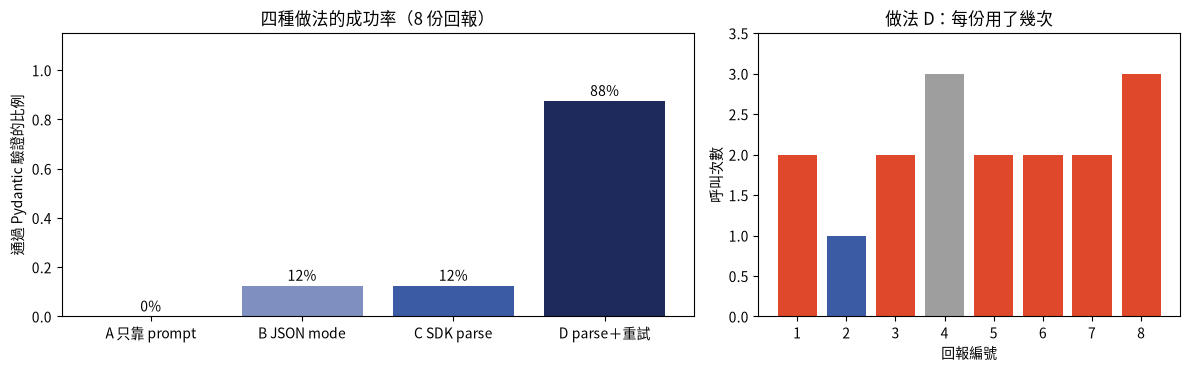

In [9]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

names = list(METHODS)
pass_rate = [sum(r["ok"] for r in results[n]) / len(REPORTS) for n in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 2]})
bars = ax1.bar(names, pass_rate, color=["#9e9e9e", "#7f8fbf", "#3b5ba5", "#1f2a5c"])
for b, v in zip(bars, pass_rate):
    ax1.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center")
ax1.set_ylim(0, 1.15)
ax1.set_ylabel("通過 Pydantic 驗證的比例")
ax1.set_title("四種做法的成功率（8 份回報）")

d = results["D parse＋重試"]
colors = ["#3b5ba5" if r["ok"] and r["tries"] == 1 else "#e0482c" if r["ok"] else "#9e9e9e" for r in d]
ax2.bar(range(1, len(d) + 1), [r["tries"] for r in d], color=colors)
ax2.set_xticks(range(1, len(d) + 1))
ax2.set_xlabel("回報編號")
ax2.set_ylabel("呼叫次數")
ax2.set_ylim(0, 3.5)
ax2.set_title("做法 D：每份用了幾次")
plt.tight_layout()
plt.show()

A 幾乎全滅（外框與客套話）；B、C 解決了「是不是 JSON」，剩下的失敗多半是服務名稱不在目錄裡——
那是業務規則，只有 Pydantic 擋得到。錯誤訊息裡列出了合法名稱，模型照著改就過了，所以 D 的成功率最高。

## Step 9：通過驗證 ≠ 內容正確

驗證只檢查「長得對不對」。拿通過的資料和標準答案比，五個欄位各自對不對：

In [10]:
for name in names:
    passed = [r for r in results[name] if r["ok"]]
    if passed:
        acc = sum(r["correct"] for r in passed) / (len(passed) * len(FIELDS))
        print(f"{name:12s} 通過的 {len(passed)} 份裡，欄位正確率 {acc:.0%}")
    else:
        print(f"{name:12s} 沒有任何一份通過")

A 只靠 prompt  沒有任何一份通過
B JSON mode  通過的 1 份裡，欄位正確率 100%
C SDK parse  通過的 1 份裡，欄位正確率 80%
D parse＋重試   通過的 7 份裡，欄位正確率 94%


常見錯誤：「一個半小時」寫成 30 分鐘、「一小時十分鐘」寫成 60、「1.2 萬」換算成整數。
這些值格式完全合法，Pydantic 擋不住。要抓這種錯，得靠有標準答案的評估集（Lab 2-06）或更強的模型。

## 試試看

1. 把 `in_catalog` 驗證拿掉，重跑 Step 7。做法 D 還需要重試嗎？資料庫裡會多出哪些服務名稱？
2. 加一個 `field_validator`：`affected_users` 超過 100 萬就判定不合理。哪些規則該寫進 schema、哪些只能寫在程式裡？
3. 把 `PROMPT` 縮成一句「抽出事故資訊」，只靠 schema 的 `description` 說明欄位，C 的成功率會變嗎？

## 小結

- 一個 Pydantic 類別兩頭用：`parse(response_format=類別)` 或 Ollama 的 `format=schema` 約束輸出，再驗證成物件。
- 約束解碼只保證格式；schema 管不到的業務規則寫在 Pydantic，不過就回饋重試並設上限；能用程式算的欄位交給 `computed_field`；被截斷要另外處理。
- 通過驗證只代表格式對，內容對不對要另外評估。下一本 Lab 2-04 換個角度：使用者故意在輸入裡塞指令，模型會不會被帶走。